# 03 — The co-optimised dispatch model

One linear program, solved with HiGHS, that chooses energy and FCESS enablement together.

The model dispatches every five minutes because the power, state-of-charge and FCESS headroom constraints bind at five minutes, but it settles energy on the thirty-minute Reference Trading Price, because that is what the Rules settle on (ESM Rules 9.9.4). FCESS is paid per five-minute Dispatch Interval on the enablement quantity (9.10.6).

This notebook demonstrates the model on real trading days and checks the invariants on real prices. The hand-calculated toy-day cases that gate any real-data run live in `tests/test_dispatch.py` and are run first below.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import cases, data, fcess_market, viz
from src.model import SERVICES, DispatchLP, solve_dispatch

viz.use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

## The gate: toy-day tests must pass first

In [2]:
gate = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/test_dispatch.py", "-q"],
    cwd=Path.cwd().parent,
    capture_output=True,
    text=True,
)
print(gate.stdout.strip()[-400:])
assert gate.returncode == 0, "toy-day dispatch tests failed; do not run on real data"
print("\ntoy-day tests pass")

....................................                                     [100%]

toy-day tests pass


## The headline cases

In [3]:
headline = cases.headline_cases()
pd.DataFrame(
    [
        {
            "case": label,
            "MW": p.p_max_mw,
            "hours": p.duration_h,
            "usable MWh": round((p.soc_max_frac - p.soc_min_frac) * p.energy_mwh, 1),
            "eta charge": round(p.efficiency_ch, 4),
            "$/MWh throughput": p.c_thru,
            "FCESS accredited MW": p.accredited_for("contingency_raise"),
            "capacity credits": p.has_capacity_credits,
            "credited MW": round(p.accredited_capacity_mw, 1),
        }
        for label, p in headline.items()
    ]
).set_index("case")

,MW,hours,usable MWh,eta charge,$/MWh throughput,FCESS accredited MW,capacity credits,credited MW
case,,,,,,,,
1h_merchant,100.0,1.0,90.0,0.9381,5.0,50.0,False,0.0
1h_credits,100.0,1.0,90.0,0.9381,5.0,50.0,True,21.1
2h_merchant,100.0,2.0,180.0,0.9381,5.0,50.0,False,0.0
2h_credits,100.0,2.0,180.0,0.9381,5.0,50.0,True,42.2
4h_merchant,100.0,4.0,360.0,0.9381,5.0,50.0,False,0.0
4h_credits,100.0,4.0,360.0,0.9381,5.0,50.0,True,84.4


The credited MW column is the Capacity Credit quantity each duration can hold: the energy it can sustain over the four-hour ESR Obligation Duration, net of discharge losses and the reserved state-of-charge window (ESM Rules 4.11.3, assumption C1). A one-hour battery is derated to roughly a quarter of its rating, which is the main reason short batteries earn little capacity revenue.

## How much FCESS can a new entrant actually win?

This is the most consequential modelling choice in the project, because FCESS is the larger half of a SWIS battery's revenue.

Left to its accreditation alone the optimiser holds 50 MW in each of four services in every interval — about a quarter of the entire SWIS contingency raise requirement, continuously. No battery has ever done that, and the resulting revenue is roughly an order of magnitude above anything any real battery has earned.

The published market requirement is not a usable ceiling either: in 2025 the storage fleet's contingency lower enablement averaged 134 % of it, because at a clearing price near zero the dispatch engine enables more than the minimum at no cost.

The central case therefore gives the entrant the enablement per accredited MW that the **operating** storage fleet actually achieved in each interval. That is an observation rather than an assumption about the merit order, and it moves with the competitive pressure that drove FCESS prices from $82/MWh in 2023 to near zero by 2026.

In [4]:
fleet = fcess_market.summary()
utilisation = fleet[[c for c in fleet.columns if c.endswith("utilisation")]]
utilisation.columns = [c.replace(" utilisation", "") for c in utilisation.columns]
print("enablement per accredited MW of operating storage")
utilisation.round(4)

enablement per accredited MW of operating storage


,contingency_raise,contingency_lower,regulation_raise,regulation_lower,rocof
year,,,,,
2023,0.0000,0.0000,0.0000,0.0000,0.0
2024,0.1691,0.0904,0.1599,0.0776,0.0
2025,0.3207,0.1566,0.1639,0.1461,0.0
2026,0.2572,0.1309,0.1467,0.1486,0.0


2023 is zero because no storage facility was enabled for FCESS in the first quarter after the reform. The model therefore credits a new entrant with no FCESS revenue in that quarter, which understates it; 2023 is a partial year and is excluded from the headline annual figures for that reason as well.

## One real trading day

In [5]:
prices_2024 = data.complete_trading_days(data.load_prices(start="2024-01-01", end="2024-12-31"))
dates, energy, fcess = data.price_arrays(prices_2024)
masks = data.esroi_masks(dates)
caps = cases.fcess_caps(dates, headline["2h_merchant"], "fleet")

spread = energy.max(axis=1) - energy.min(axis=1)
widest = int(np.argmax(spread))
typical = int(np.argsort(spread)[len(spread) // 2])

print(f"{len(dates):,} complete trading days in 2024")
print(f"widest spread   {pd.Timestamp(dates[widest]).date()}  ${spread[widest]:,.0f}/MWh")
print(f"median spread   {pd.Timestamp(dates[typical]).date()}  ${spread[typical]:,.0f}/MWh")
print("\nmean enablement ceiling for the entrant, MW:")
for service, value in zip(SERVICES, caps.mean(axis=(0, 2))):
    print(f"  {service:20s} {value:6.2f}")

362 complete trading days in 2024
widest spread   2024-09-12  $1,738/MWh
median spread   2024-08-15  $577/MWh

mean enablement ceiling for the entrant, MW:
  contingency_raise      8.34
  contingency_lower      4.44
  regulation_raise       7.81
  regulation_lower       3.83
  rocof                  0.00


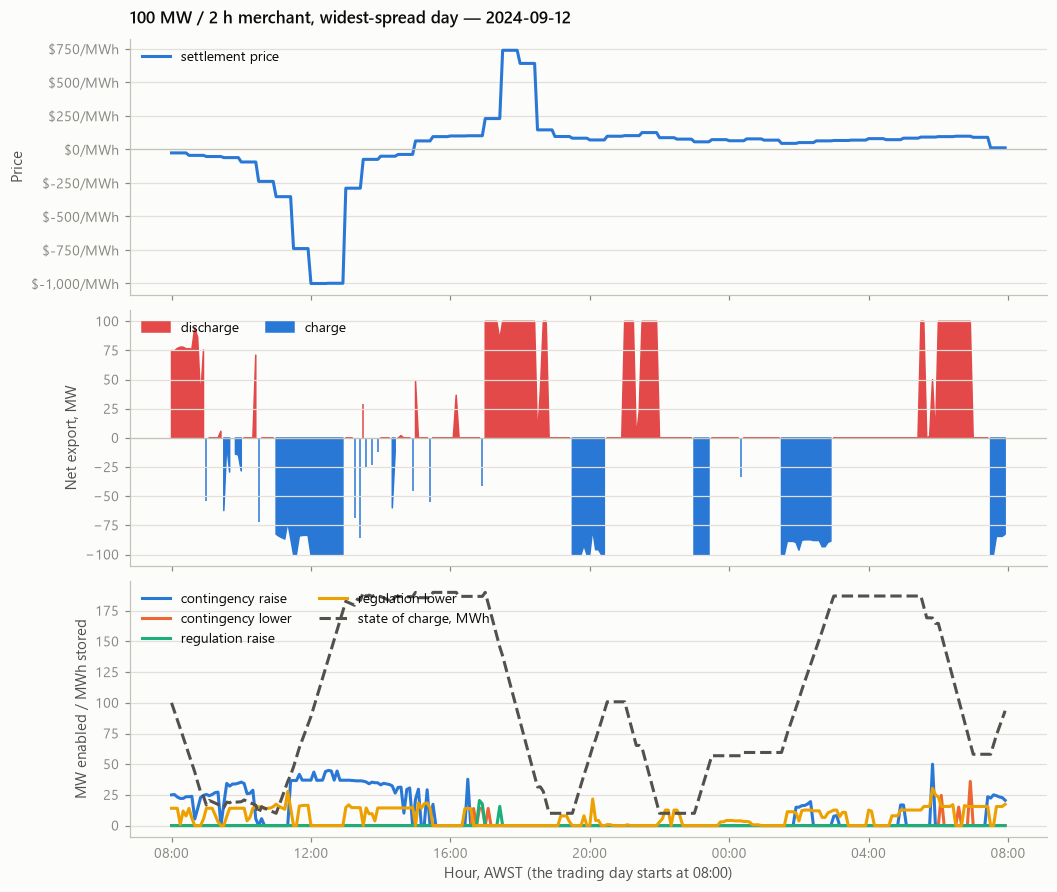

,value
status,Optimal
total_revenue,303691.015644
energy_revenue,237396.554329
fcess_revenue,70562.643921
throughput_cost,4268.182606
discharge_mwh,799.149084
charge_mwh,908.123959
cycles,4.268183
fcess_contingency_raise,50846.299758
fcess_contingency_lower,91.298325


In [6]:
def plot_day(index, params, label, *, esroi_mask=None, cap=None):
    result = solve_dispatch(
        energy[index],
        params,
        fcess_prices=fcess[index],
        esroi_mask=esroi_mask,
        fcess_cap=cap,
    )
    clock = np.arange(288) * 5 / 60 + 8  # the trading day starts at 08:00 AWST

    fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.0), sharex=True, layout="constrained")
    fig.patch.set_facecolor(viz.SURFACE)
    for ax in axes:
        ax.set_facecolor(viz.SURFACE)

    axes[0].plot(clock, energy[index], color=viz.SERIES[0], label="settlement price")
    axes[0].axhline(0, color=viz.AXIS, linewidth=0.8)
    viz.money(axes[0], unit="/MWh")
    viz.finish(axes[0], f"{label} — {pd.Timestamp(dates[index]).date()}", ylabel="Price")
    axes[0].legend(loc="upper left")

    net = result.p_dis - result.p_ch
    axes[1].fill_between(clock, 0, net, where=net >= 0, color=viz.DIVERGING_HIGH, label="discharge")
    axes[1].fill_between(clock, 0, net, where=net < 0, color=viz.DIVERGING_LOW, label="charge")
    axes[1].axhline(0, color=viz.AXIS, linewidth=0.8)
    axes[1].set_ylabel("Net export, MW")
    axes[1].legend(loc="upper left", ncols=2)

    if esroi_mask is not None and esroi_mask.any():
        inside = np.flatnonzero(esroi_mask)
        for ax in axes:
            ax.axvspan(clock[inside[0]], clock[inside[-1]], color=viz.GRID, zorder=0)
        axes[2].plot([], [], color=viz.GRID, linewidth=8, label="obligation window")

    for slot, service in enumerate(cases.OFFERED_SERVICES):
        quantity = result.enablement[service]
        if quantity.max() > 1e-6:
            axes[2].plot(clock, quantity, color=viz.SERIES[slot], label=service.replace("_", " "))
    axes[2].plot(
        clock, result.soc[:-1], color=viz.INK_SECONDARY, linestyle="--", label="state of charge, MWh"
    )
    axes[2].set_ylabel("MW enabled / MWh stored")
    axes[2].set_xlabel("Hour, AWST (the trading day starts at 08:00)")
    axes[2].set_xticks(range(8, 33, 4))
    axes[2].set_xticklabels([f"{h % 24:02d}:00" for h in range(8, 33, 4)])
    axes[2].legend(loc="upper left", ncols=2)

    plt.show()
    return result


widest_result = plot_day(
    widest, headline["2h_merchant"], "100 MW / 2 h merchant, widest-spread day", cap=caps[widest]
)
pd.Series(widest_result.summary()).to_frame("value")

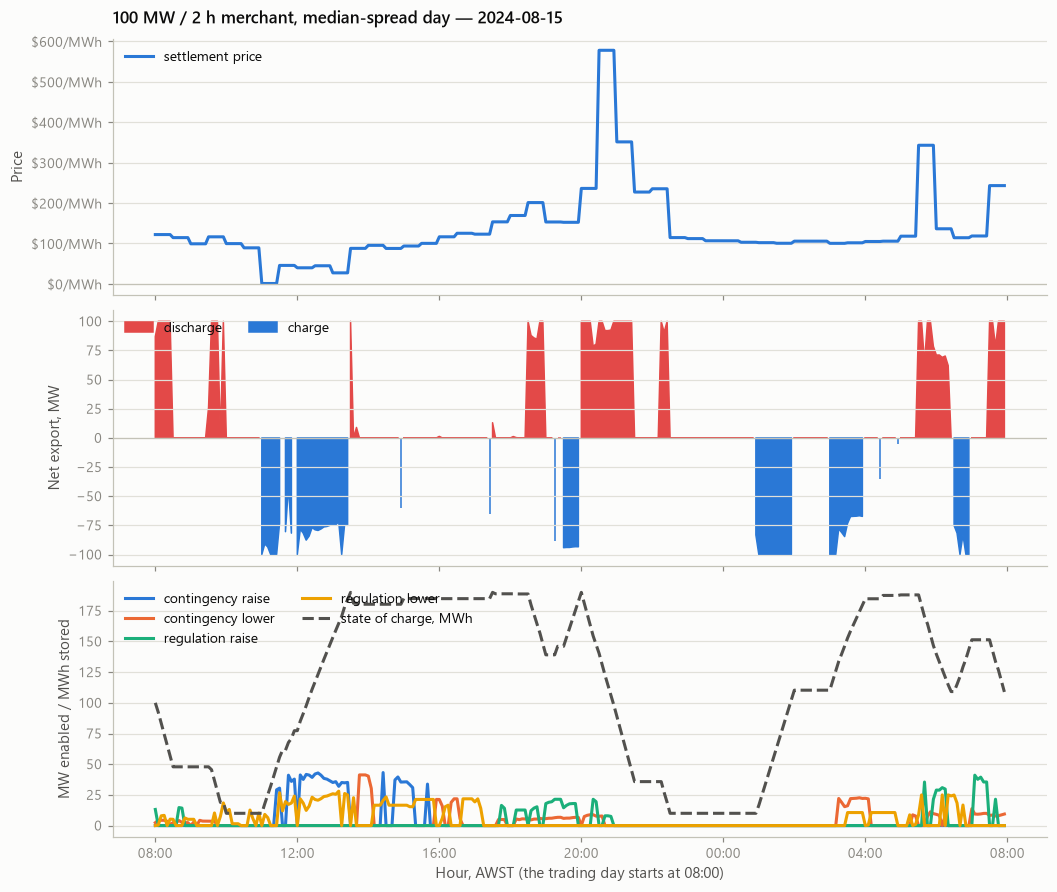

,value
status,Optimal
total_revenue,88980.674427
energy_revenue,74342.897851
fcess_revenue,16946.704726
throughput_cost,2308.928149
discharge_mwh,432.309951
charge_mwh,491.261308
cycles,2.308928
fcess_contingency_raise,4259.903842
fcess_contingency_lower,3808.793412


In [7]:
typical_result = plot_day(
    typical, headline["2h_merchant"], "100 MW / 2 h merchant, median-spread day", cap=caps[typical]
)
pd.Series(typical_result.summary()).to_frame("value")

## The obligation window, visible

The same day for a battery holding Capacity Credits. Charging is forbidden inside the shaded window and enough energy must be held when it opens to discharge at the credited capacity throughout (assumption C4).

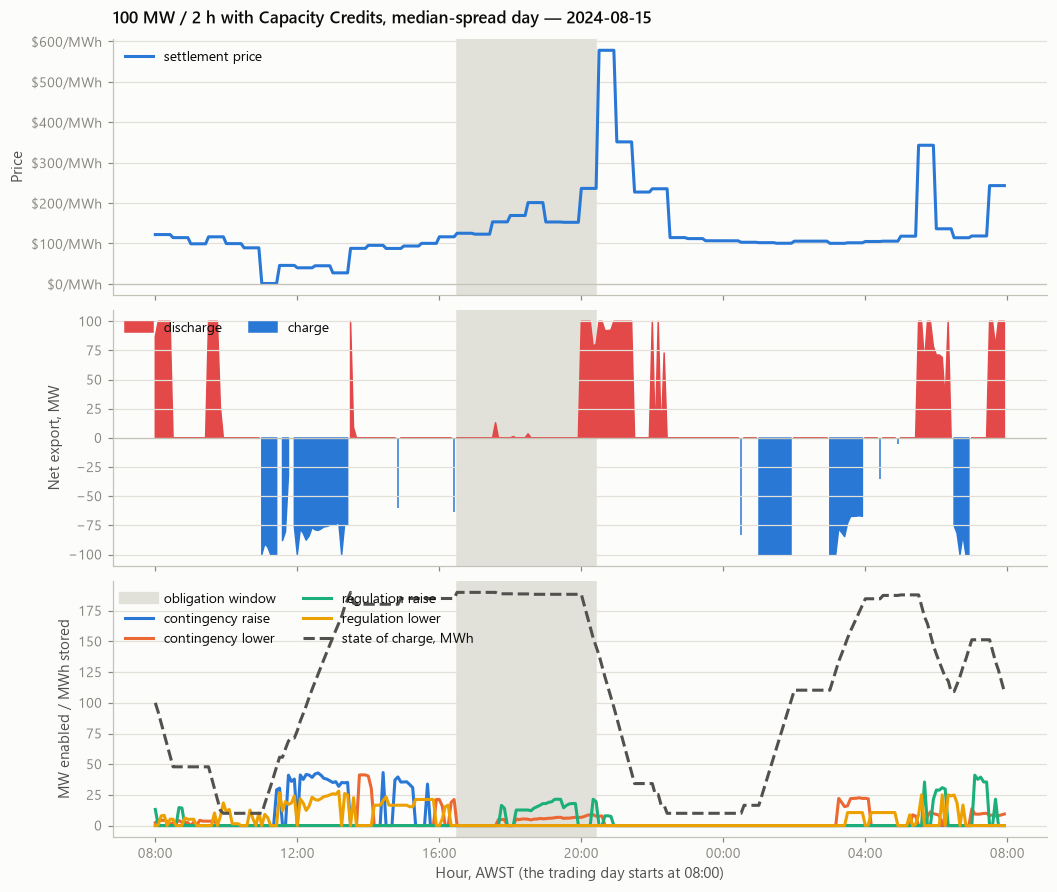

,merchant,with capacity credits
status,Optimal,Optimal
total_revenue,88980.674427,87882.384821
energy_revenue,74342.897851,72998.254847
fcess_revenue,16946.704726,16937.522951
throughput_cost,2308.928149,2053.392977
discharge_mwh,432.309951,384.465068
charge_mwh,491.261308,436.892123
cycles,2.308928,2.053393
fcess_contingency_raise,4259.903842,4259.903842
fcess_contingency_lower,3808.793412,3752.25937


In [8]:
obliged_result = plot_day(
    typical,
    headline["2h_credits"],
    "100 MW / 2 h with Capacity Credits, median-spread day",
    esroi_mask=masks[typical],
    cap=caps[typical],
)

comparison = pd.DataFrame(
    {"merchant": typical_result.summary(), "with capacity credits": obliged_result.summary()}
)
comparison.loc["obligation cost ($/day)"] = [
    0.0,
    typical_result.total_revenue - obliged_result.total_revenue,
]
comparison

## The three FCESS ceilings, side by side

How much of the answer rests on the choice made above. All three are perfect foresight on the whole of 2024 for the 100 MW / 2 h merchant case.

In [9]:
def year_total(params, cap_array=None, esroi=None) -> pd.DataFrame:
    """Perfect foresight over every day, reusing one built LP where the shape allows."""
    rows = []
    reusable = cap_array is None and esroi is None
    lp = DispatchLP(288, params) if reusable else None
    for index in range(len(dates)):
        if reusable:
            result = lp.solve(energy[index], fcess[index])
        else:
            mask = None if esroi is None else esroi[index]
            result = solve_dispatch(
                energy[index],
                params,
                fcess_prices=fcess[index],
                esroi_mask=mask,
                fcess_cap=None if cap_array is None else cap_array[index],
            )
        row = result.summary()
        row["trading_date"] = dates[index]
        rows.append(row)
    return pd.DataFrame(rows).set_index("trading_date")


ceiling_comparison = {}
for mode in cases.FCESS_CAP_MODES:
    cap_array = cases.fcess_caps(dates, headline["2h_merchant"], mode)
    frame = year_total(headline["2h_merchant"], cap_array)
    ceiling_comparison[mode] = {
        "total $m": frame["total_revenue"].sum() / 1e6,
        "energy $m": frame["energy_revenue"].sum() / 1e6,
        "FCESS $m": frame["fcess_revenue"].sum() / 1e6,
        "cycles/year": frame["cycles"].sum(),
    }

pd.DataFrame(ceiling_comparison).T.round(2)

,total $m,energy $m,FCESS $m,cycles/year
fleet,36.43,32.97,4.58,1121.06
requirement,36.07,33.04,4.15,1120.24
accreditation,97.07,26.58,71.40,905.79


The accreditation-only figure is the headline number this project would have produced had the market requirement been ignored. It is reported here precisely so that it is not mistaken for a result.

## Perfect-foresight revenue by duration, 2024

The upper bound every strategy in the next notebook is measured against.

In [10]:
annual = {}
for label, params in headline.items():
    cap_array = cases.fcess_caps(dates, params, "fleet")
    esroi = masks if params.has_capacity_credits else None
    annual[label] = year_total(params, cap_array, esroi)
    print(f"{label:14s} solved {len(annual[label]):,} days")

1h_merchant    solved 362 days


1h_credits     solved 362 days


2h_merchant    solved 362 days


2h_credits     solved 362 days


4h_merchant    solved 362 days


4h_credits     solved 362 days


In [11]:
totals = pd.DataFrame(
    {
        label: {
            "total $m": frame["total_revenue"].sum() / 1e6,
            "energy $m": frame["energy_revenue"].sum() / 1e6,
            "FCESS $m": frame["fcess_revenue"].sum() / 1e6,
            "throughput cost $m": frame["throughput_cost"].sum() / 1e6,
            "$/MW-year": frame["total_revenue"].sum() / cases.HEADLINE_MW,
            "cycles/year": frame["cycles"].sum(),
        }
        for label, frame in annual.items()
    }
).T
totals.round(2)

,total $m,energy $m,FCESS $m,throughput cost $m,$/MW-year,cycles/year
1h_merchant,27.14,23.40,4.71,0.96,271428.69,1919.27
1h_credits,26.13,22.34,4.70,0.92,261283.01,1833.23
2h_merchant,36.43,32.97,4.58,1.12,364333.50,1121.06
2h_credits,35.36,31.86,4.58,1.08,353612.10,1083.13
4h_merchant,45.78,42.69,4.44,1.35,457848.04,675.93
4h_credits,44.32,41.21,4.46,1.34,443242.41,670.54


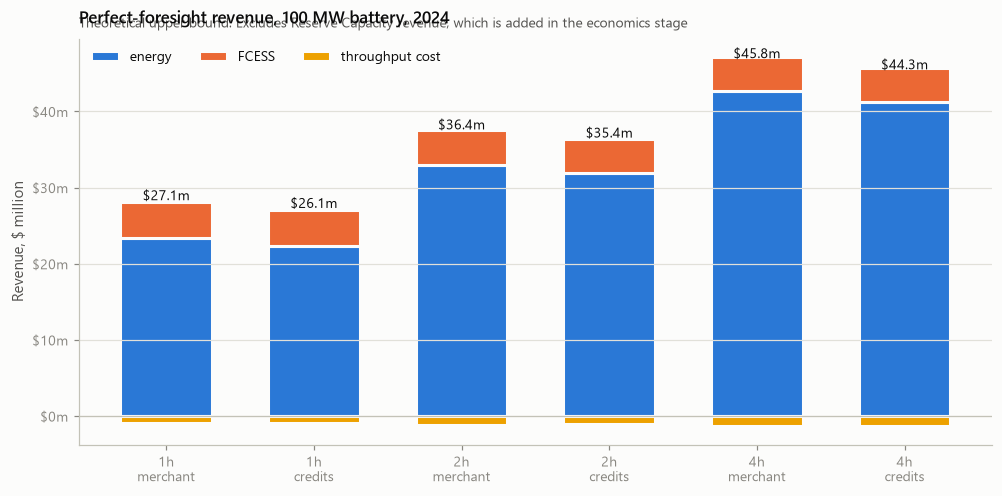

In [12]:
fig, ax = viz.figure(9.0, 4.4)

labels = list(annual)
x = np.arange(len(labels))
energy_part = np.array([annual[l]["energy_revenue"].sum() / 1e6 for l in labels])
fcess_part = np.array([annual[l]["fcess_revenue"].sum() / 1e6 for l in labels])
cost_part = np.array([annual[l]["throughput_cost"].sum() / 1e6 for l in labels])

ax.bar(x, energy_part, color=viz.SERIES[0], label="energy", width=0.62, linewidth=2, edgecolor=viz.SURFACE)
ax.bar(x, fcess_part, bottom=energy_part, color=viz.SERIES[1], label="FCESS", width=0.62, linewidth=2, edgecolor=viz.SURFACE)
ax.bar(x, -cost_part, color=viz.SERIES[3], label="throughput cost", width=0.62, linewidth=2, edgecolor=viz.SURFACE)

for position, total in zip(x, energy_part + fcess_part - cost_part):
    ax.annotate(
        f"${total:,.1f}m",
        (position, total),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
        fontsize=9,
        color=viz.INK_PRIMARY,
    )

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([l.replace("_", "\n") for l in labels])
viz.money(ax, unit="m")
viz.finish(
    ax,
    "Perfect-foresight revenue, 100 MW battery, 2024",
    subtitle="Theoretical upper bound. Excludes Reserve Capacity revenue, which is added in the economics stage",
    ylabel="Revenue, $ million",
)
ax.legend(loc="upper left", ncols=3)
plt.show()

## Invariants on real prices

The toy-day tests check these on constructed days. Re-checking on a sample of real days confirms nothing in the real price series breaks them.

In [13]:
base_params = headline["2h_merchant"]
checks = []

for index in range(0, len(dates), 11):
    common = dict(fcess_prices=fcess[index], fcess_cap=caps[index])
    base = solve_dispatch(energy[index], base_params, **common)
    costly = solve_dispatch(energy[index], cases.battery(2.0, c_thru=40.0), **common)
    efficient = solve_dispatch(
        energy[index], cases.battery(2.0, round_trip_efficiency=0.95), **common
    )
    checks.append(
        {
            "throughput cost raised revenue": costly.total_revenue > base.total_revenue + 1e-6,
            "efficiency lowered revenue": efficient.total_revenue < base.total_revenue - 1e-6,
            "soc out of bounds": bool(
                base.soc.min() < base_params.soc_min_mwh - 1e-6
                or base.soc.max() > base_params.soc_max_mwh + 1e-6
            ),
            "soc did not close": abs(base.soc[0] - base.soc[-1]) > 1e-6,
            "energy balance error": base.energy_balance_error(),
            "simultaneous charge and discharge": float(np.minimum(base.p_ch, base.p_dis).max()),
        }
    )

violations = pd.DataFrame(checks)
pd.Series(
    {
        "days checked": len(violations),
        "days where a higher throughput cost raised revenue": int(
            violations["throughput cost raised revenue"].sum()
        ),
        "days where higher efficiency lowered revenue": int(
            violations["efficiency lowered revenue"].sum()
        ),
        "days with state of charge out of bounds": int(violations["soc out of bounds"].sum()),
        "days where state of charge did not close": int(violations["soc did not close"].sum()),
        "largest energy balance error, MWh": violations["energy balance error"].max(),
        "largest simultaneous charge and discharge, MW": violations[
            "simultaneous charge and discharge"
        ].max(),
    }
).to_frame("value")

,value
days checked,3.300000e+01
days where a higher throughput cost raised revenue,0.000000e+00
days where higher efficiency lowered revenue,2.000000e+00
days with state of charge out of bounds,0.000000e+00
days where state of charge did not close,0.000000e+00
"largest energy balance error, MWh",2.842171e-14
"largest simultaneous charge and discharge, MW",1.000000e+02


Every count should be zero and both error magnitudes negligible. Simultaneous charging and discharging is not forbidden by a binary in the LP, so its magnitude is reported rather than assumed; if it were non-zero the binary would be switched on and the revenue effect reported (assumption M5).

## What settling on the five-minute price instead would have shown

A check on the single most consequential rule in the project. Settling the same model on the five-minute clearing price overstates revenue, and the size of that overstatement is the cost of getting assumption E1 wrong.

In [14]:
_, energy_5min, _ = data.price_arrays(prices_2024, settle_on=data.CLEARING_PRICE_COLUMN)

on_30min = sum(
    solve_dispatch(energy[i], base_params, fcess_prices=fcess[i], fcess_cap=caps[i]).total_revenue
    for i in range(len(dates))
)
on_5min = sum(
    solve_dispatch(
        energy_5min[i], base_params, fcess_prices=fcess[i], fcess_cap=caps[i]
    ).total_revenue
    for i in range(len(dates))
)

print(f"settled on the 30-minute Reference Trading Price   ${on_30min / 1e6:,.2f}m")
print(f"settled on the 5-minute clearing price             ${on_5min / 1e6:,.2f}m")
print(f"overstatement from using the wrong price           {on_5min / on_30min - 1:.1%}")

settled on the 30-minute Reference Trading Price   $36.43m
settled on the 5-minute clearing price             $40.24m
overstatement from using the wrong price           10.5%
